In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

VARIANT = 11
D = 5 + VARIANT % 6
LOWER, UPPER = -10.0, 10.0
POP_SIZE = 100
GENERATIONS = 300
ELITE = 2
TOURNAMENT_SIZE = 3
P_CROSSOVER = 0.9
P_MUTATION = 0.2
ALPHA = 0.5
SEEDS = list(range(11001, 11021))
EPSILON = 0.01
CONFIGS = {"ГА, σ = 0.15": 0.15, "ГА, σ = 1.00": 1.00,
           "Случайный поиск": None}
BUDGET = POP_SIZE + GENERATIONS * (POP_SIZE - ELITE)
CHECKPOINTS = POP_SIZE + np.arange(GENERATIONS + 1) * (POP_SIZE - ELITE)
OUT = Path("results")
OUT.mkdir(exist_ok=True)

assert POP_SIZE >= 30 and 1 <= ELITE < POP_SIZE
assert 0 <= P_CROSSOVER <= 1 and 0 <= P_MUTATION <= 1
assert ALPHA >= 0 and GENERATIONS > 0 and LOWER < UPPER
assert len(SEEDS) >= 20 and len(SEEDS) == len(set(SEEDS))

In [2]:
def alpine(x: np.ndarray):
    x = np.asarray(x, dtype=float)
    return np.abs(x * np.sin(x) + 0.1 * x).sum(axis=-1)


def tournament(population, values, rng):
    indices = rng.integers(0, len(population), size=TOURNAMENT_SIZE)
    return population[indices[np.argmin(values[indices])]]


def blx_crossover(parent1, parent2, rng):
    distance = np.abs(parent1 - parent2)
    low = np.minimum(parent1, parent2) - ALPHA * distance
    high = np.maximum(parent1, parent2) + ALPHA * distance
    return rng.uniform(low, high, size=(2, D))


def mutate(child, sigma, rng):
    mask = rng.random(D) < P_MUTATION
    child = child + rng.normal(0.0, sigma, size=D) * mask
    return np.clip(child, LOWER, UPPER)

In [3]:
def run_ga(seed: int, sigma: float, generations: int = GENERATIONS):
    if not np.isfinite(sigma) or sigma < 0 or generations < 0:
        raise ValueError("Масштаб мутации и число поколений должны быть неотрицательными.")
    rng = np.random.default_rng(seed)
    population = rng.uniform(LOWER, UPPER, size=(POP_SIZE, D))
    values = alpine(population)
    evaluations = POP_SIZE
    history = [float(values.min())]

    for _ in range(generations):
        elite_indices = np.argsort(values)[:ELITE]
        offspring = []
        while len(offspring) < POP_SIZE - ELITE:
            parent1 = tournament(population, values, rng)
            parent2 = tournament(population, values, rng)
            if rng.random() < P_CROSSOVER:
                children = blx_crossover(parent1, parent2, rng)
            else:
                children = (parent1, parent2)
            for child in children:
                offspring.append(mutate(child, sigma, rng))

        offspring = np.asarray(offspring[:POP_SIZE - ELITE])
        offspring_values = alpine(offspring)
        population = np.vstack((population[elite_indices], offspring))
        # Сохранённые элиты повторно не оцениваются.
        values = np.concatenate((values[elite_indices], offspring_values))
        evaluations += len(offspring)
        history.append(float(values.min()))

    best = int(np.argmin(values))
    return {"x": population[best].copy(), "fun": float(values[best]),
            "history": np.array(history), "evaluations": evaluations}

In [4]:
def random_search(seed: int):
    rng = np.random.default_rng(seed)
    points = rng.uniform(LOWER, UPPER, size=(BUDGET, D))
    values = alpine(points)
    best = int(np.argmin(values))
    history = np.minimum.accumulate(values)[CHECKPOINTS - 1]
    return {"x": points[best].copy(), "fun": float(values[best]),
            "history": history, "evaluations": len(points)}

In [5]:
assert D == 10
assert alpine(np.zeros(D)) == 0.0
np.testing.assert_allclose(alpine(np.ones(D)), D * (np.sin(1.0) + 0.1))
edge = mutate(np.full(D, 100.0), 10.0, np.random.default_rng(1))
assert np.all((edge >= LOWER) & (edge <= UPPER))
check1 = run_ga(123, 0.15, generations=5)
check2 = run_ga(123, 0.15, generations=5)
np.testing.assert_array_equal(check1["history"], check2["history"])
np.testing.assert_array_equal(check1["x"], check2["x"])
assert check1["evaluations"] == POP_SIZE + 5 * (POP_SIZE - ELITE)
assert np.all(np.diff(check1["history"]) <= 0)
print("Проверки пройдены.")

Проверки пройдены.


In [6]:
rows = []
histories = {}
for method, sigma in CONFIGS.items():
    histories[method] = []
    for seed in SEEDS:
        start = perf_counter()
        result = random_search(seed) if sigma is None else run_ga(seed, sigma)
        seconds = perf_counter() - start
        assert result["evaluations"] == BUDGET
        assert len(result["history"]) == GENERATIONS + 1
        assert np.all(np.diff(result["history"]) <= 0)
        assert np.all((result["x"] >= LOWER) & (result["x"] <= UPPER))
        np.testing.assert_allclose(alpine(result["x"]), result["fun"], atol=1e-12)
        histories[method].append(result["history"])
        row = {"method": method, "seed": seed, "best_f": result["fun"],
               "evaluations": result["evaluations"], "seconds": seconds}
        row.update({f"x{i+1}": float(x) for i, x in enumerate(result["x"])})
        rows.append(row)
    histories[method] = np.asarray(histories[method])
    print(f"{method}: {len(SEEDS)} запусков завершено")

results = pd.DataFrame(rows)
for method in CONFIGS:
    np.testing.assert_array_equal(histories[method][:, 0],
                                  histories[next(iter(CONFIGS))][:, 0])

ГА, σ = 0.15: 20 запусков завершено
ГА, σ = 1.00: 20 запусков завершено
Случайный поиск: 20 запусков завершено


In [7]:
summary = results.groupby("method", sort=False).agg(
    runs=("best_f", "size"), best=("best_f", "min"),
    mean=("best_f", "mean"), median=("best_f", "median"),
    std=("best_f", "std"), worst=("best_f", "max"),
    successes=("best_f", lambda x: int((x <= EPSILON).sum())),
    mean_seconds=("seconds", "mean")
)
display(summary.round(6))
display(results.pivot(index="seed", columns="method", values="best_f").round(6))

best_row = results.loc[results["best_f"].idxmin()]
best_x = best_row[[f"x{i+1}" for i in range(D)]].to_numpy(dtype=float)
print(f"Лучший запуск: {best_row['method']}, seed = {best_row['seed']}")
print(f"f(x) = {best_row['best_f']:.12f}")
print("x =", np.array2string(best_x, precision=12))

,runs,best,mean,median,std,worst,successes,mean_seconds
method,,,,,,,,
"ГА, σ = 0.15",20,0.002679,0.005394,0.005540,0.001072,0.008042,20,0.518891
"ГА, σ = 1.00",20,0.010018,0.029103,0.025402,0.013053,0.052372,0,0.532037
Случайный поиск,20,4.874722,6.240854,6.012069,0.750188,7.732076,0,0.007437


method,"ГА, σ = 0.15","ГА, σ = 1.00",Случайный поиск
seed,,,
11001,0.005606,0.016239,5.635571
11002,0.005755,0.029674,6.559934
11003,0.006153,0.041591,6.951752
11004,0.004869,0.049009,6.025028
11005,0.005474,0.035856,5.966312
11006,0.006253,0.042688,7.732076
11007,0.004105,0.025694,5.679060
11008,0.005421,0.024551,5.865206
11009,0.005996,0.052372,5.687384


Лучший запуск: ГА, σ = 0.15, seed = 11012
f(x) = 0.002679467587
x = [-9.567919780124e-02  4.235873317536e-03 -9.436186787137e-05
 -9.018636479697e-02 -1.089456911285e-03 -9.547282553253e-02
 -1.007516129288e-01 -1.004694555925e-01 -6.565249698082e-04
 -1.021092294889e-01]


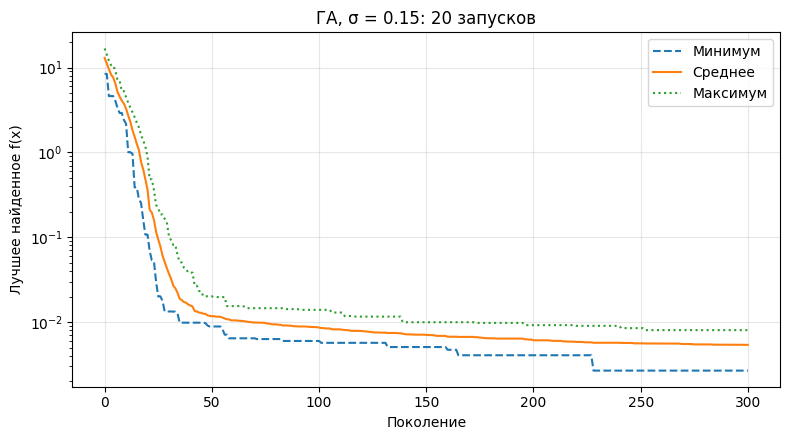

In [8]:
generations = np.arange(GENERATIONS + 1)
base_method = next(iter(CONFIGS))
history = histories[base_method]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(generations, history.min(axis=0), "--", label="Минимум")
ax.plot(generations, history.mean(axis=0), label="Среднее")
ax.plot(generations, history.max(axis=0), ":", label="Максимум")
ax.set(title=f"{base_method}: {len(SEEDS)} запусков", xlabel="Поколение",
       ylabel="Лучшее найденное f(x)", yscale="log")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "convergence.png", dpi=180)
plt.show()

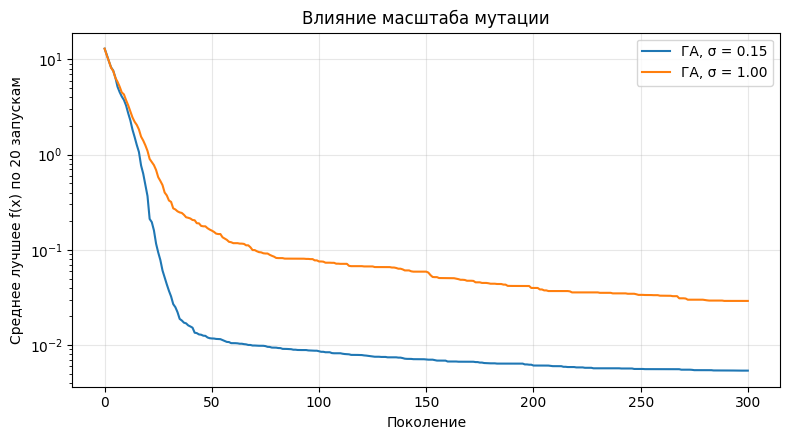

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for method, sigma in CONFIGS.items():
    if sigma is not None:
        ax.plot(generations, histories[method].mean(axis=0), label=method)
ax.set(title="Влияние масштаба мутации", xlabel="Поколение",
       ylabel="Среднее лучшее f(x) по 20 запускам", yscale="log")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "mutation_comparison.png", dpi=180)
plt.show()

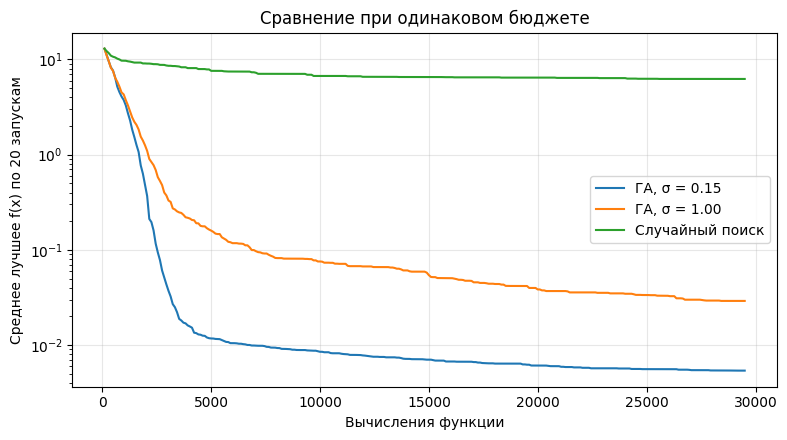

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for method in CONFIGS:
    ax.plot(CHECKPOINTS, histories[method].mean(axis=0), label=method)
ax.set(title="Сравнение при одинаковом бюджете", xlabel="Вычисления функции",
       ylabel="Среднее лучшее f(x) по 20 запускам", yscale="log")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "random_comparison.png", dpi=180)
plt.show()

In [11]:
trajectory_rows = []
for method in CONFIGS:
    for seed, history in zip(SEEDS, histories[method]):
        for generation, best_f in enumerate(history):
            trajectory_rows.append({"method": method, "seed": seed,
                                    "generation": generation,
                                    "evaluations": int(CHECKPOINTS[generation]),
                                    "best_f": float(best_f)})
results.to_csv(OUT / "runs.csv", index=False, encoding="utf-8-sig")
summary.to_csv(OUT / "summary.csv", encoding="utf-8-sig")
pd.DataFrame(trajectory_rows).to_csv(OUT / "convergence.csv", index=False,
                                    encoding="utf-8-sig")
print(f"Сохранено: {len(results)} запусков; {len(trajectory_rows)} точек траекторий.")

Сохранено: 60 запусков; 18060 точек траекторий.
